In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv



# Regression Trees and Bagging

## 1. What are Regression Trees?

Regression Trees are supervised machine learning algorithms used to predict continuous numerical values.

They are a type of Decision Tree specifically designed for regression problems.

A Regression Tree divides the dataset into smaller subsets based on feature conditions. It continues splitting the data until it reaches a stopping condition. Each final region is called a leaf node.

Unlike classification trees, which predict a class label using measures such as Gini Impurity and Entropy, Regression Trees generally use Mean Squared Error (MSE) or variance reduction to decide the best split.

The prediction at each leaf node is usually the mean of the target values belonging to that leaf.

**Example:**

Suppose we want to predict house prices using:
- Area of the house
- Number of bedrooms
- Overall quality
- Age of the house

A Regression Tree may learn rules such as:

- If house area is greater than 2000 sq. ft., move to the right branch.
- If overall quality is greater than 7, move to another branch.
- Finally, predict the average house price of the training samples in the resulting leaf.

## 2. Why do we use Regression Trees?

Traditional Linear Regression assumes a linear relationship between independent variables and the target variable.

However, real-world datasets may contain:
- Non-linear relationships.
- Complex feature interactions.
- Different patterns across different groups of observations.

Regression Trees can capture these patterns without requiring us to manually define a mathematical relationship between the features and target.

**Advantages:**
- Can capture non-linear relationships.
- Automatically identifies important splitting features.
- Requires little feature scaling or normalization.
- Easy to visualize and interpret.
- Can capture interactions between multiple features.

**Limitations:**
- Can easily overfit the training data.
- Small changes in data can produce a different tree.
- A single tree may have high variance.
- Predictions are generally constant within each leaf, producing step-like predictions.

## 3. Decision Trees vs Regression Trees

A Decision Tree is a general tree-based algorithm that can perform both classification and regression.

Regression Trees are Decision Trees used specifically for predicting continuous numerical values.

| Aspect | Classification Tree | Regression Tree |
|---|---|---|
| Target | Categorical | Continuous |
| Prediction | Class label | Numerical value |
| Splitting criteria | Gini Impurity, Entropy | MSE, variance reduction |
| Leaf output | Majority class or class probabilities | Mean target value |
| Evaluation | Accuracy, Precision, Recall, F1 | MAE, MSE, RMSE, R² |
| Example | Spam or Not Spam | House Price Prediction |

**Important:** Regression Trees are not a completely separate algorithm from Decision Trees. They are the regression version of the Decision Tree algorithm.

## 4. What is Bagging?

Bagging stands for Bootstrap Aggregating.

It is an Ensemble Learning technique that combines predictions from multiple models to improve stability and reduce variance.

Instead of training just one model on the entire dataset, Bagging trains multiple models on different bootstrap samples of the original dataset.

A bootstrap sample is created by randomly selecting observations from the original dataset with replacement.

This means:
- Some observations may appear multiple times.
- Some observations may not appear in a particular sample.
- Each model gets a slightly different training dataset.

Each model makes its own prediction, and the predictions are combined.

For regression problems, Bagging generally uses the average of all model predictions.

## 5. How does Bagging work with Regression Trees?

Bagging can use Decision Tree Regressors as its base estimators.

The process:

1. Start with the original training dataset.
2. Generate multiple bootstrap samples.
3. Train a separate Regression Tree on each bootstrap sample.
4. Pass a new observation to every trained tree.
5. Collect predictions from all trees.
6. Calculate their average to obtain the final prediction.

For example:

Suppose five Regression Trees predict the price of a house:

Tree 1: ₹40 Lakhs

Tree 2: ₹45 Lakhs

Tree 3: ₹42 Lakhs

Tree 4: ₹43 Lakhs

Tree 5: ₹50 Lakhs

Final prediction:

Average = (40 + 45 + 42 + 43 + 50) / 5

Final Prediction = ₹44 Lakhs

## 6. Single Regression Tree vs Bagging Regressor

| Aspect | Single Regression Tree | Bagging Regressor |
|---|---|---|
| Number of models | One tree | Multiple trees |
| Training data | Original training dataset | Different bootstrap samples |
| Prediction | One tree's output | Average of tree predictions |
| Variance | Generally high | Generally lower |
| Stability | Sensitive to data changes | More stable |
| Overfitting | Can overfit easily | Helps reduce variance |
| Interpretability | Easy to interpret | Harder to interpret |
| Computational cost | Low | Higher |

**Important:** Bagging does not necessarily reduce bias. Its primary purpose is to reduce variance by averaging predictions from multiple models.

## 7. Why choose Bagging over a Single Regression Tree?

A single Regression Tree can learn complex patterns, but it may also learn noise and become sensitive to small changes in the training dataset.

Bagging addresses this problem by training multiple trees on different bootstrap samples and combining their predictions.

This generally produces:
- More stable predictions.
- Reduced variance.
- Better generalization in many cases.
- Less sensitivity to individual training observations.

However, Bagging does not guarantee better performance in every dataset.

## 8. What will we implement in this notebook?

We will use the Kaggle House Prices dataset to perform the following experiments:

1. Build a Single Decision Tree Regressor.
2. Understand how the tree selects features and splits.
3. Visualize the Regression Tree.
4. Evaluate predictions using MAE, MSE, RMSE and R².
5. Experiment with hyperparameters such as max_depth and min_samples_split.
6. Build a Bagging Regressor using multiple Decision Tree Regressors.
7. Compare Single Regression Tree vs Bagging Regressor.
8. Analyze how Bagging affects model performance and variance.

### Final takeaway

- **Decision Tree:** A general algorithm for classification and regression.
- **Regression Tree:** A Decision Tree that predicts continuous numerical values.
- **Bagging:** An ensemble technique that trains multiple models on bootstrap samples and combines their predictions.
- **Bagging Regressor:** Uses multiple regression models, commonly Regression Trees, and averages their predictions to improve stability and reduce variance.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')

# Display first 5 rows
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# Dataset dimensions
print("Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
df.describe()

Shape: (1460, 81)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [4]:
# Count missing values
missing_values = df.isnull().sum()

# Display columns having missing values
missing_values[missing_values > 0].sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

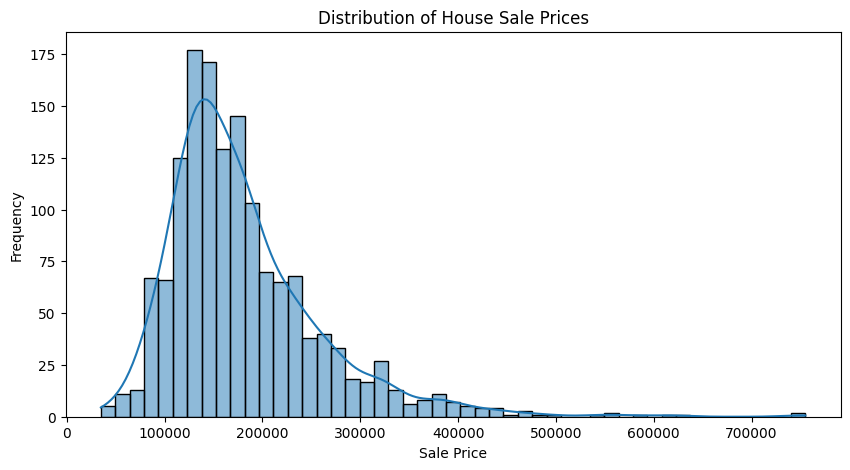

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(df['SalePrice'], kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

In [6]:
print("Mean Sale Price:", df['SalePrice'].mean())
print("Median Sale Price:", df['SalePrice'].median())
print("Minimum Sale Price:", df['SalePrice'].min())
print("Maximum Sale Price:", df['SalePrice'].max())

Mean Sale Price: 180921.19589041095
Median Sale Price: 163000.0
Minimum Sale Price: 34900
Maximum Sale Price: 755000


In [7]:
# Select numerical columns
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns

# Remove target variable and Id
numerical_features = numerical_features.drop(['SalePrice', 'Id'])

# Independent variables
X = df[numerical_features]

# Dependent variable
y = df['SalePrice']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X.head()

X Shape: (1460, 36)
y Shape: (1460,)


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,548,0,61,0,0,0,0,0,2,2008
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,460,298,0,0,0,0,0,0,5,2007
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,608,0,42,0,0,0,0,0,9,2008
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,642,0,35,272,0,0,0,0,2,2006
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,836,192,84,0,0,0,0,0,12,2008


In [8]:
# Check missing values
print("Missing values before treatment:", X.isnull().sum().sum())

# Fill missing values using median
X = X.fillna(X.median())

# Check again
print("Missing values after treatment:", X.isnull().sum().sum())

Missing values before treatment: 348
Missing values after treatment: 0


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 36)
X_test: (292, 36)
y_train: (1168,)
y_test: (292,)


In [11]:
from sklearn.tree import DecisionTreeRegressor

# Create Regression Tree model
dt_regressor = DecisionTreeRegressor(random_state=42)

# Train the model
dt_regressor.fit(X_train, y_train)

print("Regression Tree training completed!")

Regression Tree training completed!


In [12]:
# Predict house prices
y_pred = dt_regressor.predict(X_test)

# Compare actual and predicted values
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,154500,154000.0
1,325000,423000.0
2,115000,128000.0
3,159000,210000.0
4,315500,285000.0
5,75500,81000.0
6,311500,201800.0
7,146000,148500.0
8,84500,80500.0
9,135500,167500.0


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 26765.811643835616
MSE: 1490135449.9828768
RMSE: 38602.27260127151
R2 Score: 0.8057272390075647


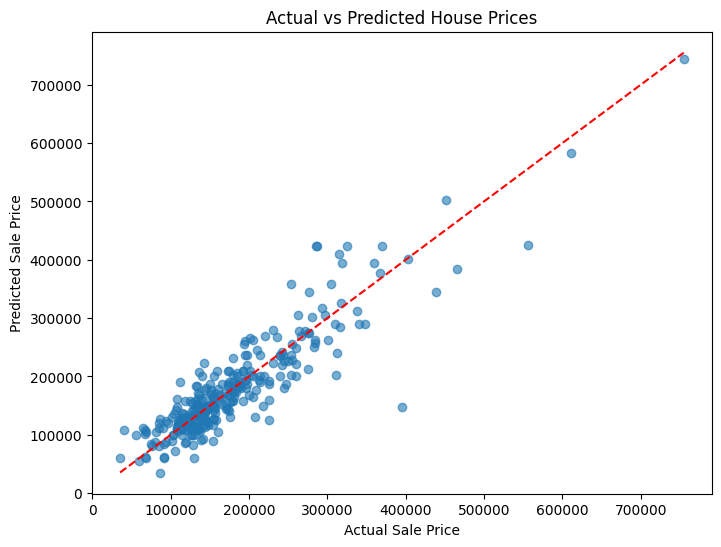

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()